# Practical 06 – Linear and Polynomial Regression Combined

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
housing = fetch_california_housing(as_frame=True)
X = housing.data[['MedInc']]


In [2]:
y = housing.target
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import PolynomialFeatures
models = {'Linear': LinearRegression(), 'Polynomial': Pipeline([('poly', PolynomialFeatures(degree=2, include_bias=False)), ('reg', LinearRegression())])}
x_line = np.linspace(X.MedInc.min(), X.MedInc.max(), 200).reshape(-1, 1)


Linear MAE: 0.629908653009376 MSE: 0.7091157771765548 R2: 0.45885918903846656
Polynomial MAE: 0.6282915588701903 MSE: 0.7032732680932146 R2: 0.46331772769346213


C:\Users\Lenovo\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\base.py:493: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(
C:\Users\Lenovo\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\base.py:493: UserWarning: X does not have valid feature names, but PolynomialFeatures was fitted with feature names
  warnings.warn(


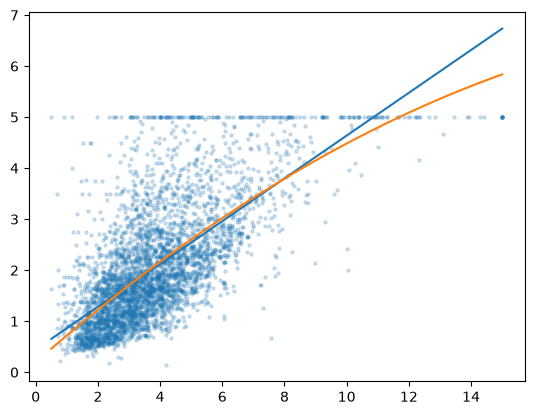

In [3]:
plt.scatter(X_test['MedInc'], y_test, s=5, alpha=0.2)
for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    print(name, 'MAE:', mean_absolute_error(y_test, pred), 'MSE:', mean_squared_error(y_test, pred), 'R2:', r2_score(y_test, pred))
    plt.plot(x_line, model.predict(x_line), label=name)


C:\Users\Lenovo\AppData\Local\Temp\ipykernel_5744\3622038522.py:1: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


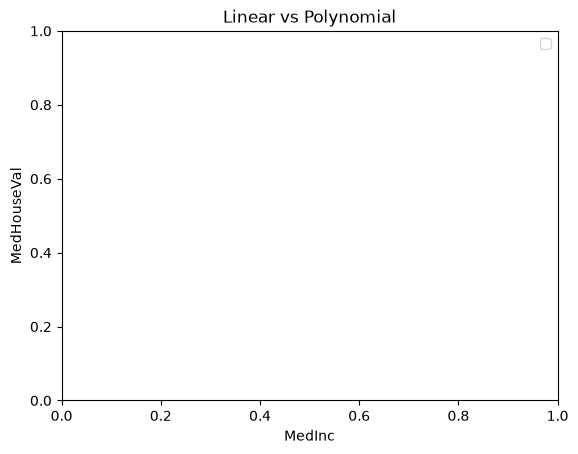

In [4]:
plt.legend()
plt.xlabel('MedInc')
plt.ylabel('MedHouseVal')
plt.title('Linear vs Polynomial')
plt.show()
